In [1]:
## --- PASO 1:Cargar los datos. Conectas Drive y abres el CSV. ---
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, classification_report, recall_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

df = pd.read_csv('/content/drive/MyDrive/dataset.csv')

df.head()

Mounted at /content/drive


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [2]:
## --- Paso 2: Revisión de la calidad de los datos ---

print("\n--- Tamaño:---", df.shape)

print("\n--- Tipos de variables ---")
df.info()

print("\n--- Valores nulos ---")
print(df.isnull().sum())

print("\n--- Valores duplicados ---")

print("Número de duplicados del dataset:", df.duplicated().sum())
df = df.drop_duplicates()

# **Descripción:** El dataset tiene 4,424 estudiantes y 35 columnas. Casi todas son numéricas, pero varias son códigos que representan categorías
# (por ejemplo `Course`, `Marital status` y `Application mode`). La única columna de texto es `Target`. No hay valores nulos ni registros duplicados,
# por lo que no fue necesario imputar ni eliminar filas.


--- Tamaño:--- (4424, 35)

--- Tipos de variables ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null  

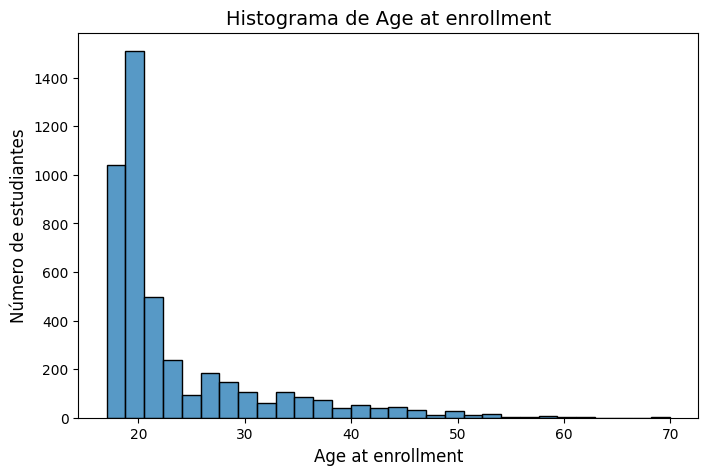

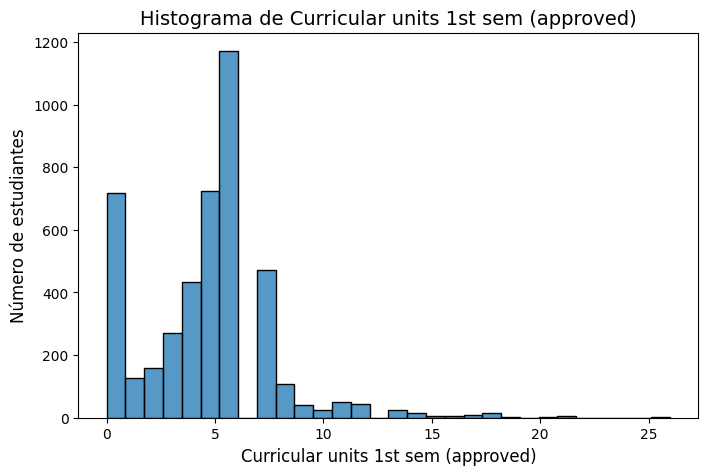

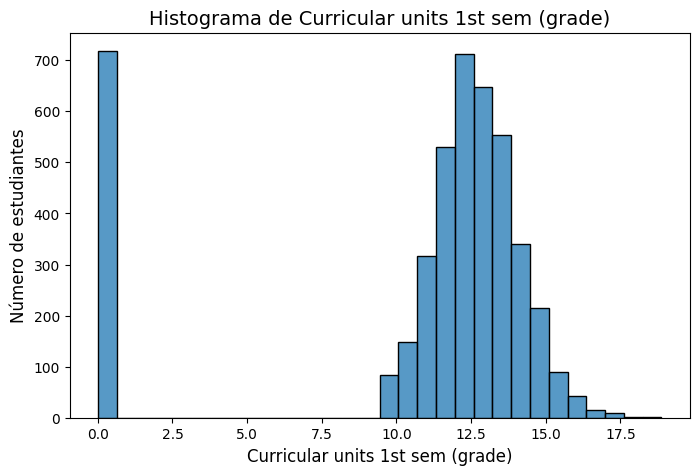

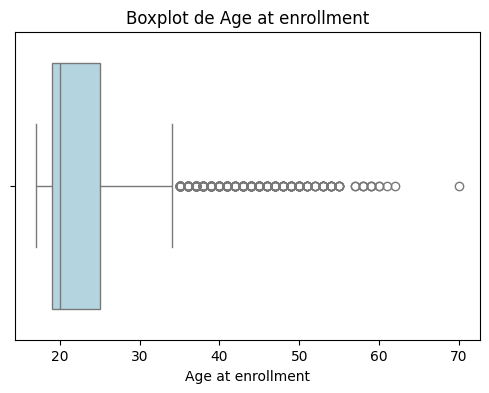

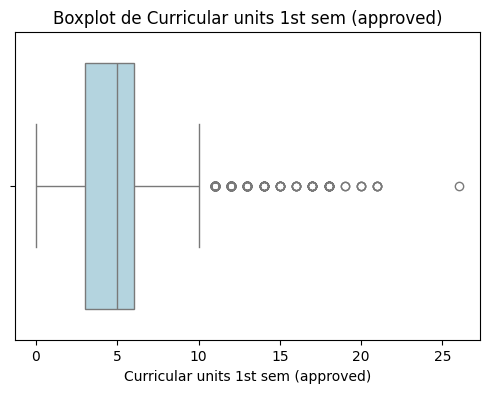

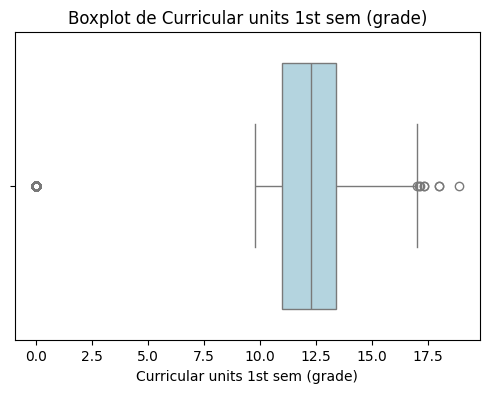

In [3]:
# ---  Paso 3: Análisis descriptivo ---
# 3.1 Estadística descriptiva

cols_numericas = [
    'Age at enrollment',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)'
]

df[cols_numericas].describe().round(2)

# 3.2 Histogramas

for col in cols_numericas:
    plt.figure(figsize=(8,5))
    sns.histplot(data=df, x=col, bins=30, kde=False, edgecolor="black")
    plt.title(f"Histograma de {col}", fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Número de estudiantes", fontsize=12)
    plt.show()

# 3.3 Boxplots

for col in cols_numericas:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col], color="lightblue")
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)
    plt.show()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Target
Graduate    49.9
Dropout     32.1
Enrolled    17.9
Name: proportion, dtype: float64


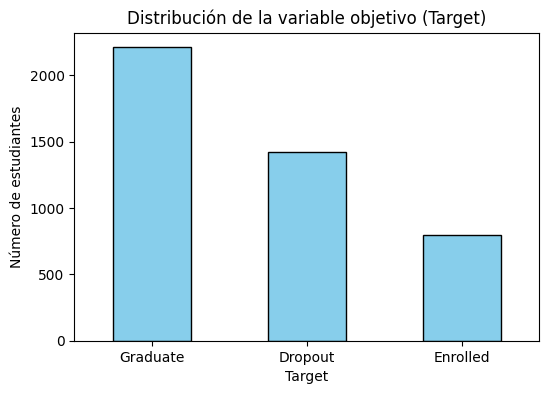


Columna: Gender
Gender
0    2868
1    1556
Name: count, dtype: int64

Columna: Scholarship holder
Scholarship holder
0    3325
1    1099
Name: count, dtype: int64

Columna: Debtor
Debtor
0    3921
1     503
Name: count, dtype: int64

Columna: Tuition fees up to date
Tuition fees up to date
1    3896
0     528
Name: count, dtype: int64

Columna: Displaced
Displaced
1    2426
0    1998
Name: count, dtype: int64

Columna: International
International
0    4314
1     110
Name: count, dtype: int64

Columna: Daytime/evening attendance
Daytime/evening attendance
1    3941
0     483
Name: count, dtype: int64

Columna: Educational special needs
Educational special needs
0    4373
1      51
Name: count, dtype: int64


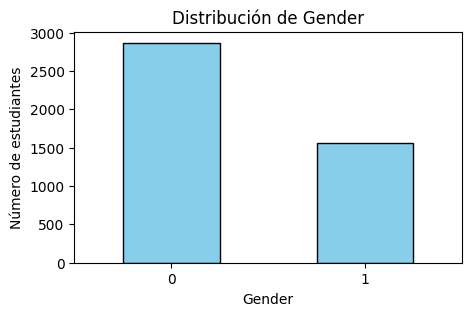

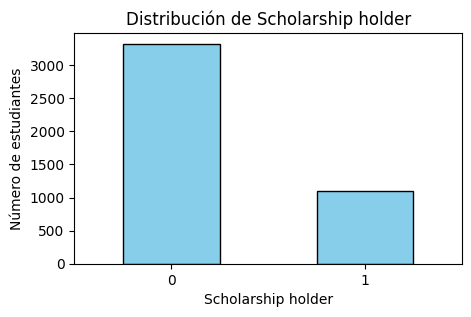

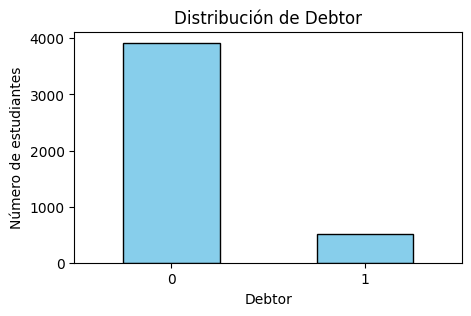

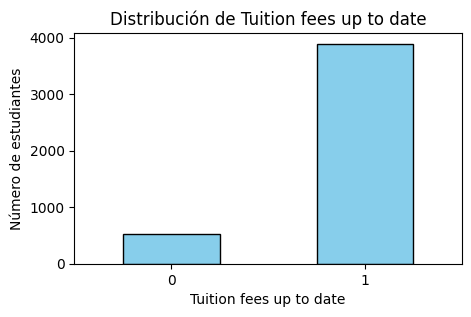

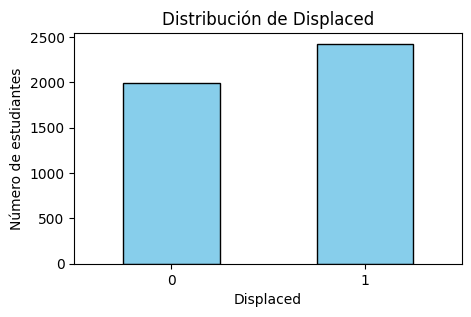

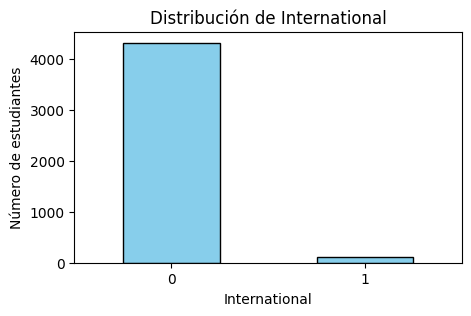

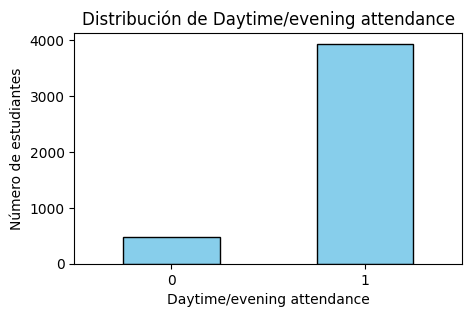

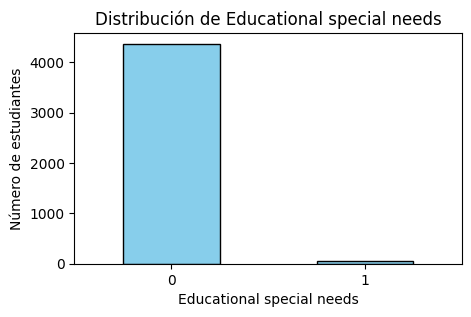

In [4]:
# --- Paso 4: Variable objetivo y variables de sí/no ---

# 4.1 Conteo de la variable objetivo
print(df['Target'].value_counts())
print((df['Target'].value_counts(normalize=True) * 100).round(1))

# 4.2 Gráfico de barras de la variable objetivo
plt.figure(figsize=(6,4))
df['Target'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Distribución de la variable objetivo (Target)')
plt.xlabel('Target')
plt.ylabel('Número de estudiantes')
plt.xticks(rotation=0)
plt.show()

# 4.3 Conteo de las variables de sí/no
cols_binarias = ['Gender', 'Scholarship holder', 'Debtor', 'Tuition fees up to date',
                 'Displaced', 'International', 'Daytime/evening attendance',
                 'Educational special needs']

for col in cols_binarias:
    print(f"\nColumna: {col}")
    print(df[col].value_counts())

# 4.4 Gráficos de barras de las variables de sí/no
for col in cols_binarias:
    plt.figure(figsize=(5,3))
    df[col].value_counts().sort_index().plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(f'Distribución de {col}')
    plt.xlabel(col)
    plt.ylabel('Número de estudiantes')
    plt.xticks(rotation=0)
    plt.show()


Tasa de abandono según Gender:
Gender
0    25.1
1    45.1
Name: abandona, dtype: float64

Tasa de abandono según Scholarship holder:
Scholarship holder
0    38.7
1    12.2
Name: abandona, dtype: float64

Tasa de abandono según Debtor:
Debtor
0    28.3
1    62.0
Name: abandona, dtype: float64

Tasa de abandono según Tuition fees up to date:
Tuition fees up to date
0    86.6
1    24.7
Name: abandona, dtype: float64

Tasa de abandono según Displaced:
Displaced
0    37.6
1    27.6
Name: abandona, dtype: float64

Tasa de abandono según International:
International
0    32.2
1    29.1
Name: abandona, dtype: float64

Tasa de abandono según Daytime/evening attendance:
Daytime/evening attendance
0    42.9
1    30.8
Name: abandona, dtype: float64

Tasa de abandono según Educational special needs:
Educational special needs
0    32.1
1    33.3
Name: abandona, dtype: float64


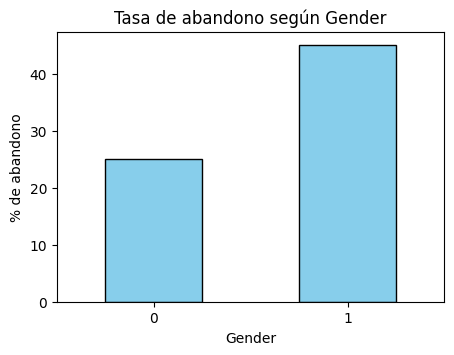

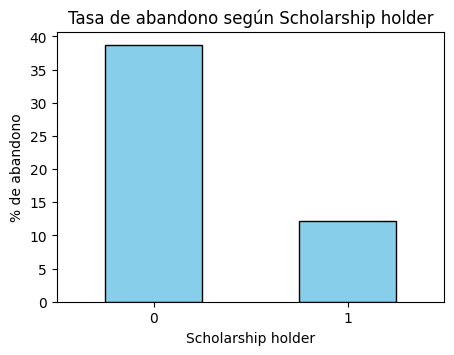

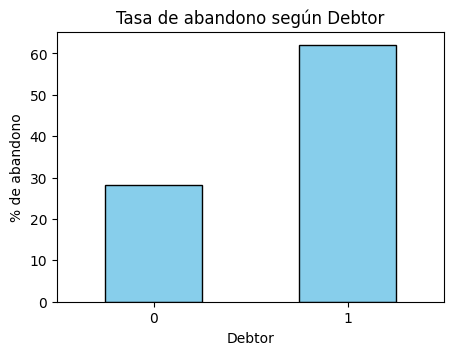

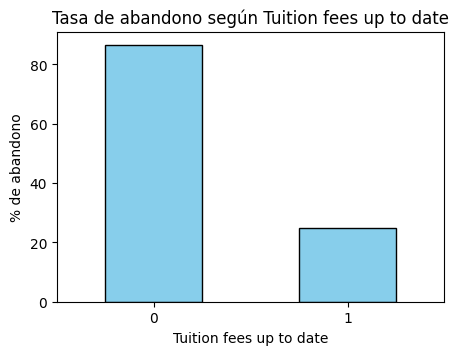

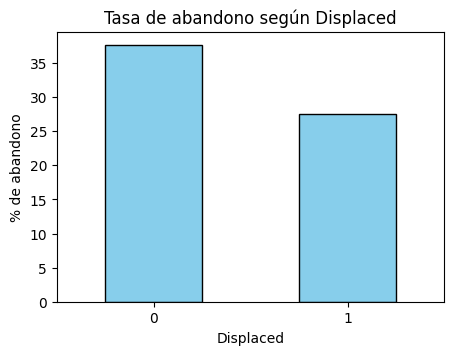

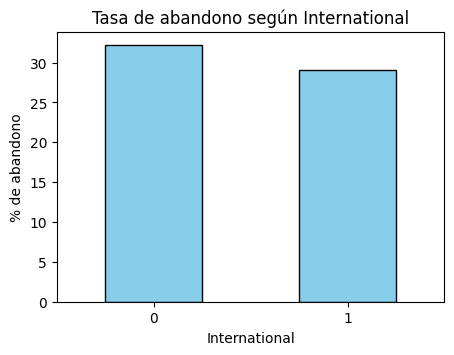

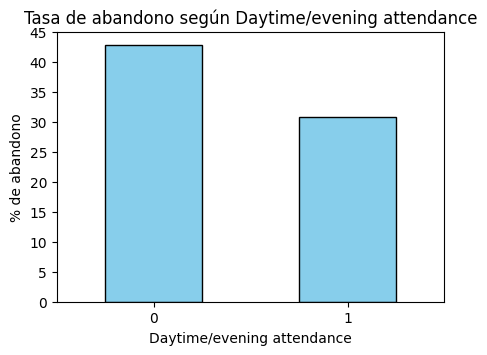

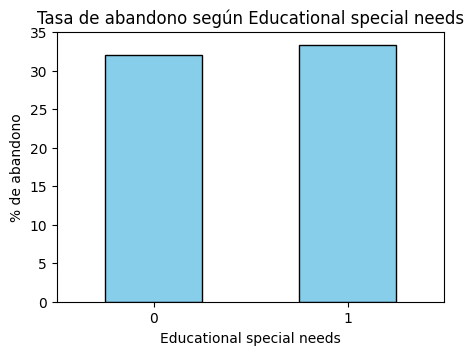

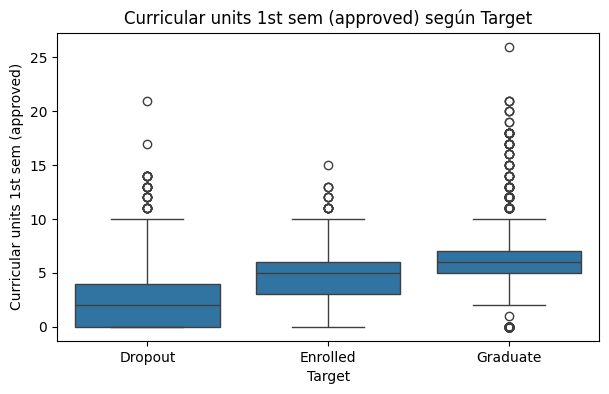

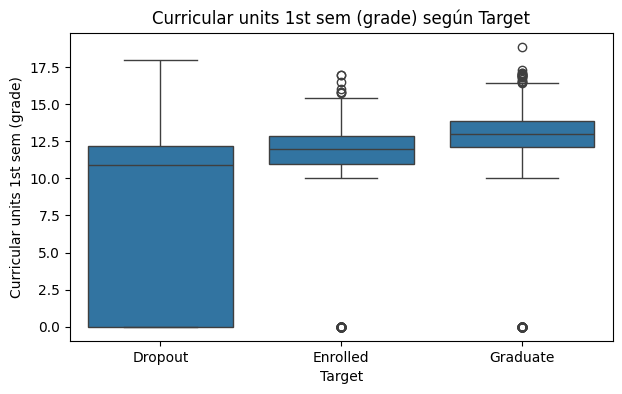

In [5]:
# --- Paso 5: Relación de las variables con el abandono ---

# Columna auxiliar: 1 si el estudiante abandonó, 0 si no (solo para explorar)
df['abandona'] = (df['Target'] == 'Dropout').astype(int)

# 5.1 Porcentaje de abandono según cada variable de sí/no
for col in cols_binarias:
    print(f"\nTasa de abandono según {col}:")
    print((df.groupby(col)['abandona'].mean() * 100).round(1))

# 5.2 Gráficos de barras de la tasa de abandono
for col in cols_binarias:
    plt.figure(figsize=(5,3.5))
    (df.groupby(col)['abandona'].mean() * 100).plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(f'Tasa de abandono según {col}')
    plt.xlabel(col)
    plt.ylabel('% de abandono')
    plt.xticks(rotation=0)
    plt.show()

# 5.3 Materias aprobadas y notas según el Target
for col in ['Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)']:
    plt.figure(figsize=(7,4))
    sns.boxplot(x='Target', y=col, data=df, order=['Dropout', 'Enrolled', 'Graduate'])
    plt.title(f'{col} según Target')
    plt.show()


Tasa de abandono según Gender:
Gender
0    25.1
1    45.1
Name: abandona, dtype: float64

Tasa de abandono según Scholarship holder:
Scholarship holder
0    38.7
1    12.2
Name: abandona, dtype: float64

Tasa de abandono según Debtor:
Debtor
0    28.3
1    62.0
Name: abandona, dtype: float64

Tasa de abandono según Tuition fees up to date:
Tuition fees up to date
0    86.6
1    24.7
Name: abandona, dtype: float64

Tasa de abandono según Displaced:
Displaced
0    37.6
1    27.6
Name: abandona, dtype: float64

Tasa de abandono según International:
International
0    32.2
1    29.1
Name: abandona, dtype: float64

Tasa de abandono según Daytime/evening attendance:
Daytime/evening attendance
0    42.9
1    30.8
Name: abandona, dtype: float64

Tasa de abandono según Educational special needs:
Educational special needs
0    32.1
1    33.3
Name: abandona, dtype: float64


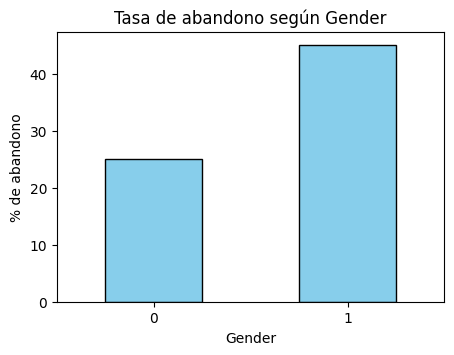

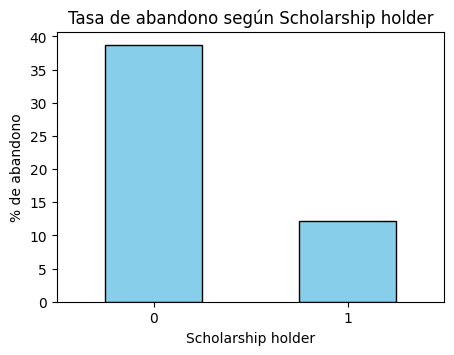

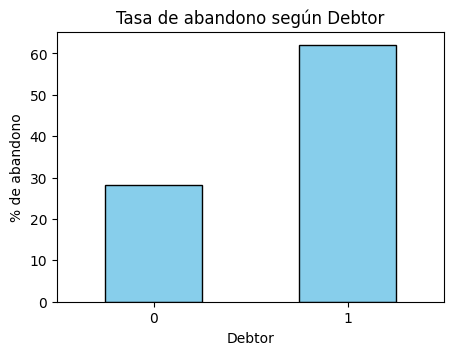

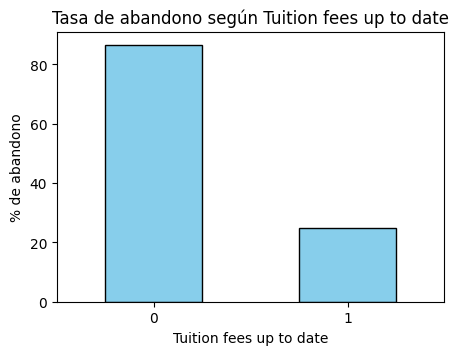

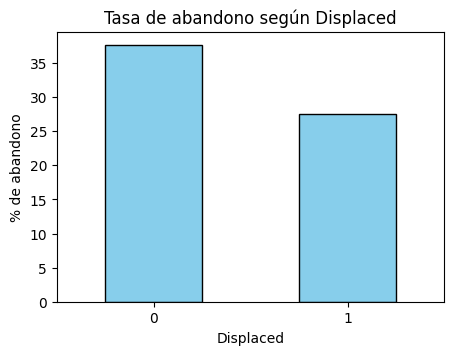

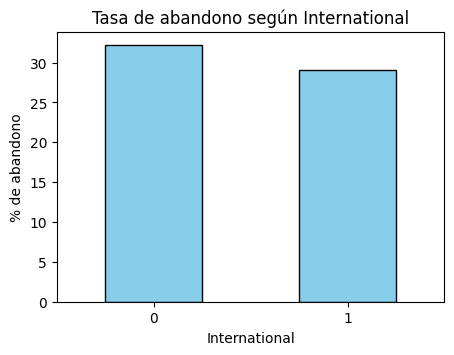

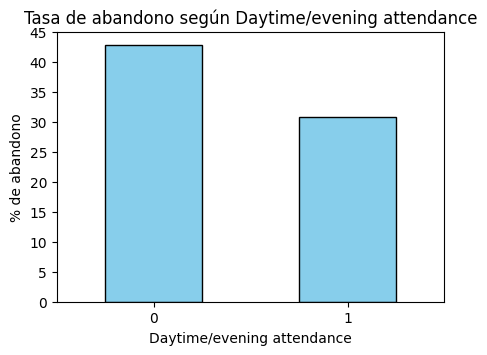

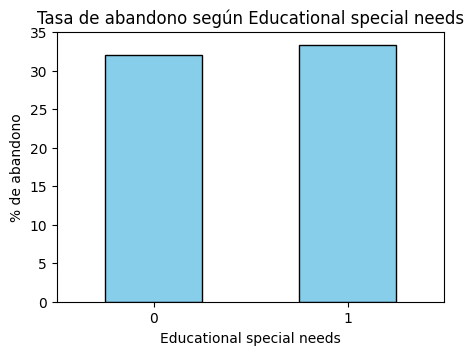

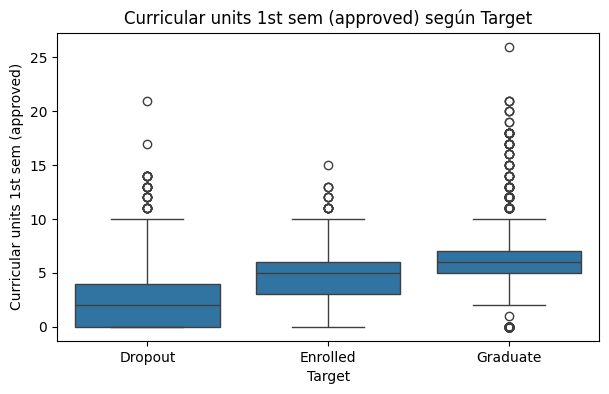

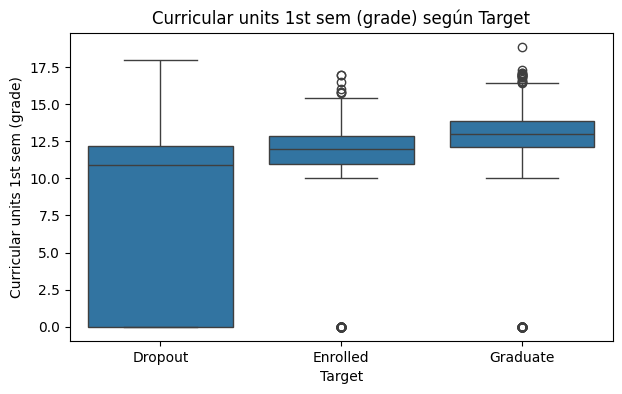

In [6]:
# --- Paso 5: Relación de las variables con el abandono ---

# Columna auxiliar: 1 si el estudiante abandonó, 0 si no (solo para explorar)
df['abandona'] = (df['Target'] == 'Dropout').astype(int)

# 5.1 Porcentaje de abandono según cada variable de sí/no
for col in cols_binarias:
    print(f"\nTasa de abandono según {col}:")
    print((df.groupby(col)['abandona'].mean() * 100).round(1))

# 5.2 Gráficos de barras de la tasa de abandono
for col in cols_binarias:
    plt.figure(figsize=(5,3.5))
    (df.groupby(col)['abandona'].mean() * 100).plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(f'Tasa de abandono según {col}')
    plt.xlabel(col)
    plt.ylabel('% de abandono')
    plt.xticks(rotation=0)
    plt.show()

# 5.3 Materias aprobadas y notas según el Target
for col in ['Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)']:
    plt.figure(figsize=(7,4))
    sns.boxplot(x='Target', y=col, data=df, order=['Dropout', 'Enrolled', 'Graduate'])
    plt.title(f'{col} según Target')
    plt.show()

In [7]:
## **Descripción:** El abandono general es del 32,1 %. Las variables que más se asocian con abandonar son la matrícula al día
##(86,6 % de abandono entre quienes no la tienen al día, contra 24,7 % entre quienes sí), la deuda (62,0 % contra 28,3 %) y la beca
##(12,2 % con beca contra 38,7 % sin beca). Los estudiantes que abandonaron aprobaron menos materias en el primer semestre: la mediana es 2,
##contra 6 en quienes se graduaron. Variables como ser internacional o tener necesidades educativas especiales casi no cambian la tasa de abandono,
## y además tienen muy pocos casos. Estos resultados muestran asociaciones, no causas.

In [8]:
# --- Paso 6: Variables y división en entrenamiento y prueba ---

# 6.1 Selección de variables (sin fuga de información)
cols_2do_semestre = [c for c in df.columns if '2nd sem' in c]
cols_quitar = ['Target', 'abandona'] + cols_2do_semestre

target = df['Target']
features = df.drop(columns=cols_quitar)

print("Columnas que se quitan:", cols_quitar)
print("Tamaño de features:", features.shape)

# 6.2 División en entrenamiento y prueba
features_train, features_test, target_train, target_test = train_test_split(
    features, target, test_size=0.25, random_state=54321, stratify=target
)

print("Entrenamiento:", features_train.shape, "| Prueba:", features_test.shape)
print("\nProporción de Target en entrenamiento:")
print(target_train.value_counts(normalize=True).round(3))
print("\nProporción de Target en prueba:")
print(target_test.value_counts(normalize=True).round(3))

Columnas que se quitan: ['Target', 'abandona', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']
Tamaño de features: (4424, 28)
Entrenamiento: (3318, 28) | Prueba: (1106, 28)

Proporción de Target en entrenamiento:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64

Proporción de Target en prueba:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.180
Name: proportion, dtype: float64


In [9]:
# --- Paso 7: Preprocesamiento (pipeline) ---

# 7.1 Clasificar las 28 variables en tres grupos
cat_cols = ['Marital status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality',
            "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]

bin_cols = ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
            'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']

num_cols = ['Application order', 'Age at enrollment',
            'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)',
            'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)',
            'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)',
            'Unemployment rate', 'Inflation rate', 'GDP']

# Comprobación: no se perdió ni se repitió ninguna columna
print(len(cat_cols), len(bin_cols), len(num_cols), "-> total:", len(cat_cols) + len(bin_cols) + len(num_cols))
assert set(cat_cols + bin_cols + num_cols) == set(features.columns)

# 7.2 Qué hacer con cada grupo
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# 7.3 Juntar todo
preprocess = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols),
    ('bin', 'passthrough', bin_cols)
])

# 7.4 Probar que funciona
preprocess.fit(features_train)
print("Entrenamiento:", preprocess.transform(features_train).shape)
print("Prueba:", preprocess.transform(features_test).shape)

9 8 11 -> total: 28
Entrenamiento: (3318, 222)
Prueba: (1106, 222)


In [10]:
# --- Paso 8: Entrenar los tres modelos ---

# 8.1 Modelo 1: Regresión Logística balanceada
lr_model = Pipeline(steps=[
    ('preprocessing', preprocess),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=54321))
])

lr_model.fit(features_train, target_train)
lr_pred = lr_model.predict(features_test)
lr_proba = lr_model.predict_proba(features_test)

# 8.2 Modelo 2: Random Forest balanceado
rf_model = Pipeline(steps=[
    ('preprocessing', preprocess),
    ('classifier', RandomForestClassifier(n_estimators=400, class_weight='balanced',
                                          random_state=54321, n_jobs=-1))
])

rf_model.fit(features_train, target_train)
rf_pred = rf_model.predict(features_test)
rf_proba = rf_model.predict_proba(features_test)

# 8.3 Modelo 3: Gradient Boosting
gb_clf = GradientBoostingClassifier(
    learning_rate=0.05,
    n_estimators=300,
    max_depth=3,
    subsample=0.9,
    random_state=54321
)

gb_model = Pipeline(steps=[
    ('prep', preprocess),
    ('clf', gb_clf)
])

# Pesos balanceados, porque Enrolled tiene menos estudiantes
gb_sw = compute_sample_weight(class_weight='balanced', y=target_train)
gb_model.fit(features_train, target_train, clf__sample_weight=gb_sw)

gb_pred = gb_model.predict(features_test)
gb_proba = gb_model.predict_proba(features_test)

# Revisar que funcionó
print("Clases:", lr_model.classes_)
print("Predicciones de ejemplo (Regresión Logística):", lr_pred[:5])

Clases: ['Dropout' 'Enrolled' 'Graduate']
Predicciones de ejemplo (Regresión Logística): ['Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate']


----- Regresión Logística -----
F1 macro: 0.699 | AUC: 0.874 | Recall macro: 0.702

Reporte de clasificación:
              precision    recall  f1-score   support

     Dropout       0.84      0.72      0.78       355
    Enrolled       0.44      0.56      0.49       199
    Graduate       0.83      0.82      0.83       552

    accuracy                           0.74      1106
   macro avg       0.70      0.70      0.70      1106
weighted avg       0.76      0.74      0.75      1106



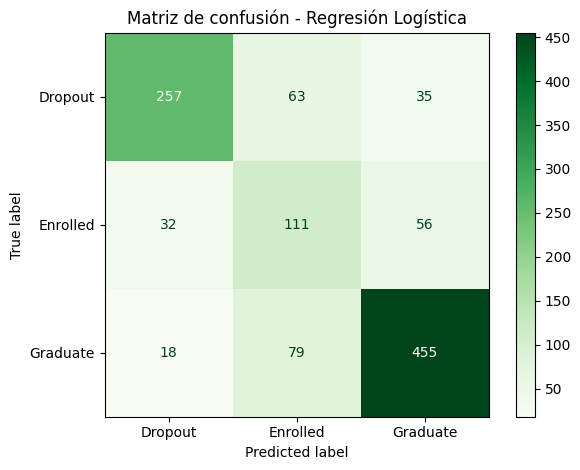

----- Random Forest -----
F1 macro: 0.654 | AUC: 0.878 | Recall macro: 0.648

Reporte de clasificación:
              precision    recall  f1-score   support

     Dropout       0.82      0.77      0.79       355
    Enrolled       0.58      0.23      0.33       199
    Graduate       0.75      0.95      0.84       552

    accuracy                           0.76      1106
   macro avg       0.72      0.65      0.65      1106
weighted avg       0.74      0.76      0.73      1106



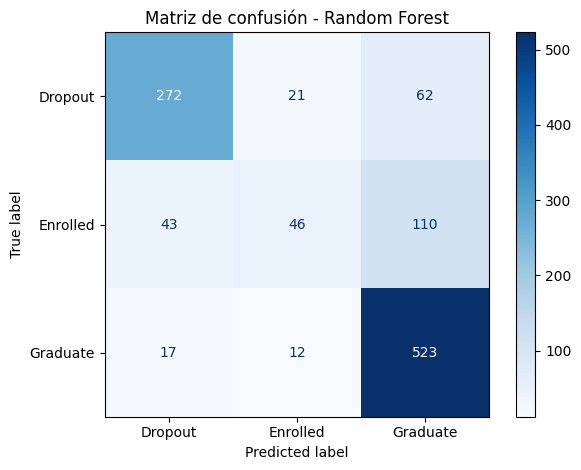

----- Gradient Boosting -----
F1 macro: 0.704 | AUC: 0.883 | Recall macro: 0.709

Reporte de clasificación:
              precision    recall  f1-score   support

     Dropout       0.85      0.70      0.77       355
    Enrolled       0.45      0.60      0.51       199
    Graduate       0.83      0.82      0.83       552

    accuracy                           0.75      1106
   macro avg       0.71      0.71      0.70      1106
weighted avg       0.77      0.75      0.75      1106



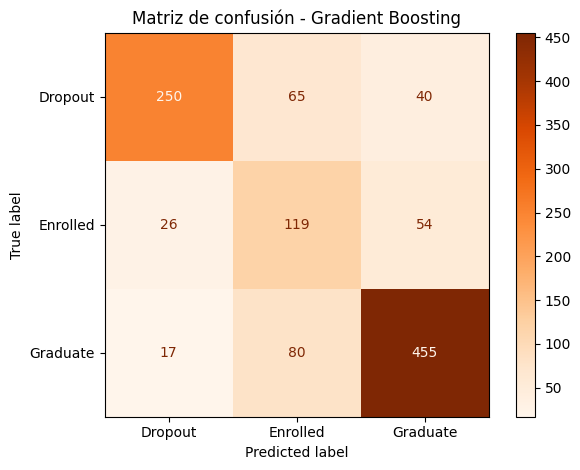

                Modelo  F1 macro    AUC  Recall macro  Recall Dropout
0  Regresión Logística     0.699  0.874         0.702           0.724
1        Random Forest     0.654  0.878         0.648           0.766
2    Gradient Boosting     0.704  0.883         0.709           0.704


In [11]:
# --- Paso 9: Evaluación de los modelos ---

etiquetas = ['Dropout', 'Enrolled', 'Graduate']

# 9.1 Una función que evalúa un modelo y dibuja su matriz de confusión
def evaluar(nombre, pred, proba, color):
    print(f"----- {nombre} -----")
    print("F1 macro:", round(f1_score(target_test, pred, average='macro'), 3),
          "| AUC:", round(roc_auc_score(target_test, proba, multi_class='ovr'), 3),
          "| Recall macro:", round(recall_score(target_test, pred, average='macro'), 3))

    print("\nReporte de clasificación:")
    print(classification_report(target_test, pred))

    cm = confusion_matrix(target_test, pred, labels=etiquetas)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=etiquetas).plot(cmap=color)
    plt.title(f"Matriz de confusión - {nombre}")
    plt.tight_layout()
    plt.show()

evaluar("Regresión Logística", lr_pred, lr_proba, "Greens")
evaluar("Random Forest", rf_pred, rf_proba, "Blues")
evaluar("Gradient Boosting", gb_pred, gb_proba, "Oranges")

# 9.2 Comparación final
metricas = []
for nombre, pred, proba in (("Regresión Logística", lr_pred, lr_proba),
                            ("Random Forest", rf_pred, rf_proba),
                            ("Gradient Boosting", gb_pred, gb_proba)):
    metricas.append({
        "Modelo": nombre,
        "F1 macro": f1_score(target_test, pred, average='macro'),
        "AUC": roc_auc_score(target_test, proba, multi_class='ovr'),
        "Recall macro": recall_score(target_test, pred, average='macro'),
        "Recall Dropout": recall_score(target_test, pred, labels=['Dropout'], average=None)[0]
    })

comparativa = pd.DataFrame(metricas)
print(comparativa.round(3))

In [12]:
## 6. Conclusiones

### 6.1 Selección del mejor modelo

## El modelo elegido es **Gradient Boosting**, porque obtuvo el mejor F1 macro (0,704) y el mejor AUC (0,883) de los tres, lo que indica que rinde bien en las tres categorías y ordena correctamente a los estudiantes según su riesgo. Para la categoría Dropout alcanzó una precisión de 0,85 y un recall de 0,70: de cada 10 estudiantes que realmente abandonan, detecta a 7, y cuando avisa que alguien abandonará, acierta en 8 o 9 de cada 10 casos.

## La Regresión Logística quedó casi empatada (F1 macro 0,699) y tiene la ventaja de ser más fácil de interpretar. Random Forest detectó mejor a quienes abandonan (recall 0,766), pero casi no detectó a los estudiantes Enrolled (recall 0,23), por lo que no funciona bien para las tres categorías a la vez.

## Con 1.106 estudiantes de prueba, la diferencia entre Gradient Boosting y Regresión Logística es pequeña, por lo que no debe considerarse concluyente.

In [13]:
### 6.2 Interpretación de los factores de riesgo

## El análisis exploratorio muestra que el abandono (32,1 % en general) se asocia con:

## **Rendimiento del primer semestre:** el 40 % de los estudiantes que abandonaron no aprobó ninguna materia, frente a solo el 3,5 % de quienes se graduaron.
## **Situación económica:** entre quienes no tienen la matrícula al día, abandona el 86,6 %; entre quienes tienen deuda, el 62,0 %.
## **Beca:** con beca abandona el 12,2 %, y sin beca el 38,7 %.
## **Jornada:** en jornada nocturna abandona el 42,9 %, contra el 30,8 % en jornada diurna.

## En cambio, variables como ser estudiante internacional o tener necesidades educativas especiales casi no cambian la tasa de abandono, y además tienen muy pocos casos (110 y 51). Estos resultados muestran asociaciones, no causas.

In [14]:
### 6.3 Recomendaciones

## 1. **Alerta temprana al terminar el primer semestre:** contactar de inmediato a los estudiantes que no aprobaron ninguna materia, con tutorías y acompañamiento, porque son el grupo con mayor riesgo.
## 2. **Seguimiento de pagos:** ofrecer planes de pago o apoyo a los estudiantes con la matrícula atrasada o con deuda, antes de que abandonen.
## 3. **Apoyo económico:** evaluar ampliar las becas o ayudas para estudiantes en riesgo, ya que quienes tienen beca abandonan menos (aunque este dato no prueba que la beca sea la causa).
## 4. **Uso responsable del modelo:** el modelo es un apoyo para priorizar a quién acompañar, no para tomar decisiones automáticas sobre un estudiante.

### 6.4 Limitaciones y próximos pasos

## - Los datos provienen de una institución de educación superior de Portugal, por lo que los resultados no se pueden generalizar directamente a otros países.
## - La categoría Enrolled es la más difícil de predecir en los tres modelos.
## - La evaluación usa una sola división de entrenamiento y prueba. Como siguiente paso se podría aplicar validación cruzada, ajustar los parámetros de los modelos y probar umbrales de decisión distintos.